# Selección de variables para el modelado del precio de bolsa

## Objetivo de este notebook

Decidir **qué variables entran a los modelos** del trabajo (SARIMAX, XGBoost, LSTM y el híbrido BiLSTM) para pronosticar el **precio medio del `precio_bolsa` en los 30 días siguientes**, y dejar documentado **por qué** cada variable entra o se descarta.

- `datasets/procesado/4_dataset_seleccion.csv`: el conjunto de variables seleccionadas, listo para modelar.
- Las tablas de importancia y de decisión que sustentan la selección, para el documento.

## Punto de partida

El notebook parte de **`2_dataset_procesado.csv`**: el dataset diario, ya imputado y sin nulos, con las variables de calendario.

## Por qué hace falta una selección y por qué en este orden

El EDA mostró tres cosas que hacen que **no baste con ordenar las variables por correlación**.

1. **Hay redundancia.**
2. **La correlación en nivel engaña.**
3. **El precio es muy persistente**

| # | Paso | Qué hace | Por qué |
|---|---|---|---|
| 1 | **Depuración con evidencia del EDA** | Descarta variables que son identidades, tienen un problema de calidad, comparten tendencia sin relación causal o usan información futura | Son decisiones que se pueden comprobar con los datos y que ningún método de importancia debería tener que descubrir |
| 2 | **Colinealidad: correlación por pares y VIF** | Poda las variables redundantes, conservando la más relacionada con el precio | La permutación se distorsiona con variables gemelas; hay que quitar la redundancia **antes** de medir importancia |
| 3 | **Construcción de candidatas** | Rezagos, medias móviles y cambios de cada variable; calendario de la fecha objetivo; variables de ruido como control | La información útil para predecir a 30 días está en la dinámica reciente, no solo en el valor de hoy |
| 4 | **Importancia por permutación agrupada, fuera de muestra** | Mide cuánto empeora el error al desordenar cada variable (junto con sus derivadas), en 5 periodos de validación temporal | Es la medida de aporte al pronóstico que usan Guo et al. (2025); captura relaciones no lineales; agrupar resuelve el reparto entre gemelas |
| 5 | **Regla de selección y revisión de dominio** | Conserva la variable si supera al ruido, es consistente entre periodos y es estable entre semillas; revisa con una ablación las que el EDA marcó como dudosas | Una regla explícita y reproducible evita elegir "lo que se ve importante" |
| 6 | **SHAP** | Reparte cada predicción entre las variables, con signo, magnitud y por régimen ENSO (El Niño, Neutral, La Niña) | Responde *cómo* influye cada variable, que es el propósito del trabajo; es el enfoque de Cu et al. (2025) |

## Relación con la matriz comparativa de métodos

`Comparativa_Metodos_Seleccion_Variables.xlsx` comparó seis métodos.

- **Correlación por pares y VIF**
- **Importancia por permutación**
- **SHAP** : no selecciona; **interpreta** la selección.
- **PCA** no se usa: reduce a componentes y se pierde la explicación de las variables originales, y explicar qué factores mueven el precio de bolsa es un propósito del trabajo (indicación del director).
- **XGBoost multivista y MLFS**

## 1. Configuración y lectura de los datos

**Qué se hace.** Se importan las librerías, se fijan los parámetros del protocolo y se lee `2_dataset_procesado.csv`, comprobando que cumple lo que el resto del notebook da por supuesto.

- `HORIZONTE = 30` días: el horizonte de mediano plazo del trabajo.
- `FIN_ENTRENAMIENTO = 2022-12-31` e `INICIO_PRUEBA = 2023-02-01`: el último origen que puede usarse para ajustar o validar, y el primero de la prueba.
- **Cinco periodos de validación**
- **Cinco semillas.**

In [1]:
# ============================================================
# Imports, rutas y parámetros del protocolo
# ============================================================
import os
import pathlib
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor
from xgboost import XGBRegressor

# Se silencian avisos de bibliotecas (p. ej. divisiones por cero del VIF cuando hay identidades exactas,
# que aquí son precisamente un hallazgo y se reportan de forma explícita).
warnings.filterwarnings("ignore")

abspath = pathlib.Path.cwd()
RUTA_DATOS = os.path.join(abspath, "datasets")
PROC = os.path.join(RUTA_DATOS, "procesado")
print("Directorio de trabajo:", abspath)

# ============================================================
# La escala de página de las figuras
# ============================================================
# El documento inserta toda figura al ancho de su columna, 6.332.220 EMU = 6,92 pulgadas. Una
# figura dibujada a 9 pulgadas cabe ahí, pero ENCAJADA: se reduce al 77 %, y con ella su
# resolución efectiva. Dibujarla directamente al ancho de la página hace que cada punto
# tipográfico sea un punto de verdad y que la densidad sea la misma que en el resto.
#
# La resolución del render EN LÍNEA no la fija el figsize ni savefig.dpi, sino la de la propia
# figura, que vale 100 mientras no se diga otra cosa: el backend en línea llama a print_figure
# con dpi=fig.dpi de forma explícita. Por eso `a_escala` la fija sobre la figura.
PPP_PAGINA, ANCHO_PX = 186, 1289
ANCHO_PAGINA = ANCHO_PX / PPP_PAGINA                     # 6,93 pulgadas

# EL RECORTE DEL BACKEND EN LINEA DESHACE ESTA ESCALA, y hay que desactivarlo. Por omision la
# figura se guarda con bbox_inches="tight", es decir ajustada a su contenido y no al tamano que se
# le dio: con letra pequena eso recorta unos pixeles de margen, pero con letra del cuerpo del
# documento los rotulos no caben en el lienzo y la imagen se ENSANCHA. Una imagen mas ancha
# insertada en el mismo ancho de columna tiene mas pixeles por pulgada, luego su letra se ve mas
# pequena: la rejilla de distribuciones pasaba de 1289 a 1633 pixeles y sus 10 puntos se veian a
# 7,9. Sin recorte, cada figura sale a ANCHO_PAGINA x PPP_PAGINA y un punto del dibujo es un punto
# del papel. El reparto del espacio lo hace `tight_layout`, que es lo que ya se llama.
try:
    get_ipython().run_line_magic(
        "config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass                                   # ejecutado como script: no hay backend en linea


def alto_pagina(ancho_viejo, alto_viejo):
    """El alto que conserva la proporción de la figura al llevarla al ancho de la página."""
    return ANCHO_PAGINA * alto_viejo / ancho_viejo


def a_escala(fig, cuerpo=10.0):
    """Lleva la figura a la escala de la pagina: resolucion y tamaños de letra.

    EL CUERPO ES EL DEL DOCUMENTO, 10 puntos, y no uno menor. Una figura se inserta al ancho de
    la columna, de modo que a esta escala cada punto tipografico es un punto sobre el papel: si
    la figura se dibuja con letra de 7, el lector la ve a 7 junto a un texto de 10 y no la lee
    impresa. Los numeros de los ejes y la leyenda van al mismo cuerpo que el texto, sin descuento,
    y solo el titulo sube un punto por encima.

    LO QUE NO QUEPA CON ESA LETRA SOBRA DE LA FIGURA. El tamaño no se baja para que entre un
    rotulo largo; se acorta el rotulo, o se le da mas alto a la figura.

    Se llama ANTES de tight_layout, para que el reparto del espacio cuente ya con el tamaño
    definitivo del texto.
    """
    fig.set_dpi(PPP_PAGINA)
    for ax in fig.get_axes():
        ax.title.set_fontsize(cuerpo + 1.0)
        ax.xaxis.label.set_fontsize(cuerpo)
        ax.yaxis.label.set_fontsize(cuerpo)
        ax.tick_params(axis="both", labelsize=cuerpo)
        for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
            etiqueta.set_fontsize(cuerpo)
        leyenda = ax.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(cuerpo)
    return fig


HORIZONTE = 30                                   # días; horizonte de mediano plazo del trabajo
# Las fronteras se alinean a PERIODOS COMPLETOS: el ONI, el IPC, el IPP y el precio de escasez son
# series mensuales propagadas a diario, y la evaluación se segmenta por fase ENSO, que también se
# define sobre meses. Cortar a mitad de mes dejaría días sueltos con el valor de un mes que queda
# del otro lado de la frontera.
FIN_ENTRENAMIENTO = pd.Timestamp("2022-12-31")   # último origen que puede ajustar o validar
INICIO_PRUEBA = pd.Timestamp("2023-02-01")       # primer origen de prueba
# El hueco entre ambos —todo enero de 2023, 31 días— es el EMBARGO: no pertenece a ninguno de los dos.
# Cada origen tiene por objetivo los 30 días siguientes, así que sin ese hueco los objetivos de los últimos
# orígenes de validación caerían dentro de la prueba.
N_PRUEBA_PROTOCOLO = 1155                        # orígenes de prueba (2023-02-01 a 2026-03-31; 20,1 %)

# Cada pliegue: (fin del ajuste, inicio de la validación, fin de la validación). Se ajusta con todo lo
# anterior (ventana expansiva) y se valida en el bloque siguiente, siempre hacia adelante en el tiempo.
PLIEGUES = [("2012-12-31", "2013-01-01", "2014-12-31"),
            ("2014-12-31", "2015-01-01", "2016-12-31"),
            ("2016-12-31", "2017-01-01", "2018-12-31"),
            ("2018-12-31", "2019-01-01", "2020-12-31"),
            ("2020-12-31", "2021-01-01", "2022-12-31")]   # cierra en año completo, como los otros cuatro
SEMILLAS = [42, 43, 44, 45, 46]   # semillas del algoritmo: miden la estabilidad de la selección
N_REPS = 10                       # repeticiones de cada permutación (promedia el azar del desorden)

Directorio de trabajo: C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB


In [2]:
# ============================================================
# Lectura de 2_dataset_procesado.csv y comprobaciones de integridad
# ============================================================
df = pd.read_csv(os.path.join(PROC, "2_dataset_procesado.csv"), parse_dates=["fecha"])
df = df.sort_values("fecha").reset_index(drop=True)

# El resto del notebook construye rezagos y diferencias con shift/diff: eso solo es válido si la serie
# es diaria, continua y sin nulos. Se comprueba en vez de suponerlo.
assert df.isna().sum().sum() == 0, "Se esperaba un dataset sin nulos"
assert (df["fecha"].diff().dropna().dt.days == 1).all(), "La serie debe ser diaria y continua"

CALENDARIO = ["tipo_dia", "dia_semana", "dia_mes", "mes"]   # categóricas/cíclicas: se tratan aparte
print(f"Dimensiones: {df.shape[0]} días x {df.shape[1]} columnas")
print(f"Rango: {df['fecha'].min().date()} a {df['fecha'].max().date()}")
print("\nColumnas:", [c for c in df.columns if c != "fecha"])

Dimensiones: 5964 días x 30 columnas
Rango: 2010-01-01 a 2026-04-30

Columnas: ['precio_bolsa', 'demanda', 'disp_dec_hidraulica', 'disp_dec_no_termica', 'disp_dec_termica', 'disponibilidad_declarada', 'gen_hidraulica', 'gen_no_termica', 'gen_termica', 'generacion', 'aportes_energia', 'precio_oferta', 'precio_escasez', 'vol_util', 'indice_ONI', 'indice_ONI_publicado', 'vertimientos', 'ipc_nivel', 'ipc_variacion_interanual', 'ipp_mineria_nivel', 'ipp_importados_nivel', 'ipp_general_nivel', 'ipp_mineria_variacion_interanual', 'ipp_importados_variacion_interanual', 'ipp_general_variacion_interanual', 'dia_semana', 'dia_mes', 'mes', 'tipo_dia']


## 2. Depuración de variables con la evidencia del EDA

**Qué se hace.** Antes de medir ninguna importancia se descartan las variables cuyo problema ya se puede **demostrar con los datos**.

| Familia | Variables | Problema | Comprobación |
|---|---|---|---|
| Identidades contables | `generacion`, `disponibilidad_declarada` | Son la suma exacta de sus componentes: VIF infinito, información duplicada | Se verifica numéricamente la identidad |
| Tendencia compartida | `ipc_nivel`, `ipp_*_nivel` | Su correlación en nivel con el precio (~0,40) es producto de la tendencia común y desaparece al quitarla | Se compara la correlación en nivel con la de los **cambios a 30 días** |
| Información futura | `indice_ONI` (centrado) | El ONI centrado usa datos de hasta dos meses posteriores a cada fecha | Se usa en su lugar `indice_ONI_publicado`, que solo ve lo que NOAA ya había publicado |

### 2.1 Identidades contables

In [3]:
# ============================================================
# 2.1 Identidades contables: ¿generacion y disponibilidad_declarada son sumas de sus partes?
# ============================================================
# generacion fue construida en 2_DataProcessing como la SUMA de las tres tecnologías. Si la diferencia
# es del orden del error de redondeo, no aporta información nueva respecto a sus componentes.
suma_gen = df["gen_hidraulica"] + df["gen_termica"] + df["gen_no_termica"]
dif_rel = ((df["generacion"] - suma_gen).abs() / df["generacion"]).max()
print(f"generacion vs. suma de sus 3 componentes: diferencia relativa máxima = {dif_rel:.2e}")

# La disponibilidad se agregaba con PROMEDIO por recurso, de modo que el total no era la suma de
# los tipos (ver 2.2). Desde la corrección del 18/10/2026 en 2_DataProcessing se agrega con SUMA,
# igual que la generación, así que ahora también es una identidad exacta.
suma_disp = df["disp_dec_hidraulica"] + df["disp_dec_termica"] + df["disp_dec_no_termica"]
dif_rel_disp = ((df["disponibilidad_declarada"] - suma_disp).abs() / df["disponibilidad_declarada"]).max()
print(f"disponibilidad_declarada vs. suma de sus 3 componentes: diferencia relativa máxima = "
      f"{dif_rel_disp:.2e}")

generacion vs. suma de sus 3 componentes: diferencia relativa máxima = 3.59e-16
disponibilidad_declarada vs. suma de sus 3 componentes: diferencia relativa máxima = 0.00e+00


**Lectura.** Los dos totales son la suma exacta de sus tres componentes: las diferencias relativas son del orden del error de redondeo.

### 2.2 Calidad de datos: la disponibilidad declarada

> **Esta sección documenta un defecto que ya está corregido.** Se conserva porque es la evidencia que > justificó la corrección, y porque explica por qué las cifras de disponibilidad anteriores al 18/10/2026 > no son comparables con las actuales.

In [4]:
# ============================================================
# 2.2 Prueba de la hipótesis: ¿cambia el número de recursos que reportan disponibilidad?
# ============================================================
# Se leen los datos crudos de XM (DispoDeclarada.csv es grande, ~160 MB; tarda unos segundos).
# Por recurso y día: disponibilidad = promedio de las 24 horas. Luego, por trimestre y tipo de recurso,
# se compara (a) cuántos recursos reportan, (b) el PROMEDIO por recurso (lo que usa el dataset) y
# (c) la SUMA diaria (la cantidad que sí tiene sentido físico).
ruta_raw = os.path.join(RUTA_DATOS, "DispoDeclarada.csv")
ruta_rec = os.path.join(RUTA_DATOS, "listado_recursos.csv")
horas = [f"Values_Hour{str(i).zfill(2)}" for i in range(1, 25)]

if os.path.exists(ruta_raw) and os.path.exists(ruta_rec):
    raw = pd.read_csv(ruta_raw, usecols=["Date", "Values_code"] + horas)
    raw["Date"] = pd.to_datetime(raw["Date"])
    raw["disp"] = raw[horas].mean(axis=1)
    catalogo = pd.read_csv(ruta_rec)[["Values_Code", "Values_Type"]].rename(columns={"Values_Code": "Values_code"})
    raw = raw.merge(catalogo, on="Values_code", how="left")
    raw["trimestre"] = raw["Date"].dt.to_period("Q")
    # Misma clasificación en tres tipos que usa 2_DataProcessing: HIDRAULICA, TERMICA y NO TERMICA (el resto).
    raw["tipo"] = np.where(raw["Values_Type"] == "TERMICA", "TERMICA",
                           np.where(raw["Values_Type"] == "HIDRAULICA", "HIDRAULICA", "NO TERMICA"))

    trimestres_vista = ["2020Q4", "2021Q2", "2021Q4", "2022Q2"]        # antes, durante y después del quiebre
    filas = []
    for tipo in ["HIDRAULICA", "TERMICA", "NO TERMICA"]:
        sub = raw[raw["tipo"] == tipo]
        g = sub.groupby("trimestre").agg(recursos=("Values_code", "nunique"), promedio_por_recurso=("disp", "mean"))
        g["suma_diaria_media"] = sub.groupby(["trimestre", "Date"])["disp"].sum().groupby("trimestre").mean()
        g.insert(0, "tipo", tipo)
        filas.append(g[g.index.astype(str).isin(trimestres_vista)])
    comprobacion = pd.concat(filas).round(0).astype({"recursos": int})
    print(comprobacion.to_string())
else:
    print("No se encontraron los datos crudos de XM; se omite la comprobación (el resultado del EDA no cambia).")

                 tipo  recursos  promedio_por_recurso  suma_diaria_media
trimestre                                                               
2020Q4     HIDRAULICA        57              167314.0          9318681.0
2021Q2     HIDRAULICA        61              168772.0          9759097.0
2021Q4     HIDRAULICA       135               82307.0         10196222.0
2022Q2     HIDRAULICA       152               70862.0         10652631.0
2020Q4        TERMICA        49               93411.0          4319256.0
2021Q2        TERMICA        49               98481.0          4599368.0
2021Q4        TERMICA        52               90555.0          4455891.0
2022Q2        TERMICA        57               75955.0          4329460.0
2020Q4     NO TERMICA        21                7454.0           138624.0
2021Q2     NO TERMICA        22                6811.0           128208.0
2021Q4     NO TERMICA        21                7434.0           148926.0
2022Q2     NO TERMICA        31                4732

- **Hidráulica:** entre 2021T2 y 2021T4 el número de recursos que reportan pasa de **61 a 135** (y a 152 en 2022T2), porque la fuente empieza a incluir plantas pequeñas.
- **Térmica:** hay un cambio de menor tamaño en el número de recursos (49 → 57), pero el promedio cae de ~98 mil a ~76 mil mientras la suma permanece cerca de 4,3–4,6 millones.
- **No térmica:**

En los tres tipos el promedio por recurso reflejaba **cuántos recursos reportan**, no cuánta disponibilidad.

### 2.3 Tendencia compartida: nivel frente a cambios a 30 días

**Qué se hace.** Para cada variable se calcula la correlación de Spearman con `precio_bolsa` de dos formas: en **nivel** y en **cambios a 30 días** (`x(t) − x(t−30)` frente a `P(t) − P(t−30)`), **solo con el entrenamiento**.

In [5]:
# ============================================================
# 2.3 Spearman con el precio: en nivel y en cambios a 30 días (solo entrenamiento)
# ============================================================
ent = df[df["fecha"] <= FIN_ENTRENAMIENTO]                    # SOLO el entrenamiento
candidatas_corr = [c for c in df.columns if c not in ["fecha", "precio_bolsa"] + CALENDARIO]
cambios30 = ent[["precio_bolsa"] + candidatas_corr].diff(30).dropna()   # x(t) - x(t-30)

filas = []
for c in candidatas_corr:
    nivel = spearmanr(ent[c], ent["precio_bolsa"]).correlation
    cambio = spearmanr(cambios30[c], cambios30["precio_bolsa"]).correlation
    filas.append((c, nivel, cambio))
corr_nivel_cambio = pd.DataFrame(filas, columns=["variable", "spearman_nivel", "spearman_cambios_30d"])
corr_nivel_cambio = corr_nivel_cambio.set_index("variable")
corr_nivel_cambio["se_debilita"] = (corr_nivel_cambio["spearman_nivel"].abs()
                                    - corr_nivel_cambio["spearman_cambios_30d"].abs())
print("Spearman con precio_bolsa, solo entrenamiento (ordenado por la correlación en cambios):")
print(corr_nivel_cambio.reindex(corr_nivel_cambio["spearman_cambios_30d"].abs()
                                .sort_values(ascending=False).index).round(2).to_string())

Spearman con precio_bolsa, solo entrenamiento (ordenado por la correlación en cambios):
                                     spearman_nivel  spearman_cambios_30d  se_debilita
variable                                                                              
gen_termica                                    0.79                  0.64         0.15
precio_oferta                                  0.63                  0.54         0.10
disponibilidad_declarada                       0.06                 -0.38        -0.32
disp_dec_hidraulica                           -0.06                 -0.37        -0.31
vol_util                                      -0.43                 -0.35         0.08
aportes_energia                               -0.48                 -0.29         0.19
gen_hidraulica                                -0.33                 -0.24         0.10
vertimientos                                  -0.57                 -0.23         0.34
demanda                                   

- **Tendencia compartida, confirmada.**
- **Relaciones robustas.**
- **El ONI**
- Con solo el entrenamiento, `gen_hidraulica` ya muestra su relación negativa en nivel (−0,33); aun así se le construyen cambios a 30 días, que es la forma que aísla el efecto sin tendencia.

### 2.4 Variables que pasan a las candidatas

Con las cuatro comprobaciones, se fija la lista de descartes con su motivo.

In [6]:
# ============================================================
# 2.4 Lista de descartes con su motivo
# ============================================================
EXCLUIDAS = {
    "generacion":               "identidad contable: suma de gen_hidraulica + gen_termica + gen_no_termica",
    "disponibilidad_declarada": "identidad contable: suma de disp_dec_hidraulica + disp_dec_termica + disp_dec_no_termica",
    # Las tres disp_dec_* se reincorporaron el 18/10/2026: el defecto de cálculo que las excluía
    # (promedio por recurso, ver 2.2) se corrigió en 2_DataProcessing y ahora se agregan con suma.
    "ipc_nivel":                "tendencia compartida: su correlación en nivel desaparece en cambios a 30 días (2.3)",
    "ipp_mineria_nivel":        "tendencia compartida (2.3)",
    "ipp_importados_nivel":     "tendencia compartida (2.3)",
    "ipp_general_nivel":        "tendencia compartida (2.3)",
    "indice_ONI":               "información futura: el ONI centrado usa datos posteriores a la fecha; se usa indice_ONI_publicado",
}
base_candidatas = [c for c in df.columns if c not in ["fecha"] + CALENDARIO and c not in EXCLUIDAS]

print(f"Descartadas ({len(EXCLUIDAS)}):")
for v, motivo in EXCLUIDAS.items():
    print(f"   {v:26s} {motivo}")
print(f"\nVariables de origen que pasan al paso 3 ({len(base_candidatas)}): {base_candidatas}")

Descartadas (7):
   generacion                 identidad contable: suma de gen_hidraulica + gen_termica + gen_no_termica
   disponibilidad_declarada   identidad contable: suma de disp_dec_hidraulica + disp_dec_termica + disp_dec_no_termica
   ipc_nivel                  tendencia compartida: su correlación en nivel desaparece en cambios a 30 días (2.3)
   ipp_mineria_nivel          tendencia compartida (2.3)
   ipp_importados_nivel       tendencia compartida (2.3)
   ipp_general_nivel          tendencia compartida (2.3)
   indice_ONI                 información futura: el ONI centrado usa datos posteriores a la fecha; se usa indice_ONI_publicado

Variables de origen que pasan al paso 3 (18): ['precio_bolsa', 'demanda', 'disp_dec_hidraulica', 'disp_dec_no_termica', 'disp_dec_termica', 'gen_hidraulica', 'gen_no_termica', 'gen_termica', 'aportes_energia', 'precio_oferta', 'precio_escasez', 'vol_util', 'indice_ONI_publicado', 'vertimientos', 'ipc_variacion_interanual', 'ipp_mineria_variacio

**Lectura.** Quedan **15 variables de origen** (de las 25 del dataset sin calendario): el precio, las variables físicas del sistema y las **cuatro variaciones interanuales** de IPC e IPP.

## 3. Colinealidad entre las variables de origen

**Qué se hace.** Sobre las variables que sobrevivieron al paso 1 se miden dos cosas, **solo con el entrenamiento**.

1. **Correlación por pares**
2. **VIF** (Factor de Inflación de Varianza, umbral 10): mide qué tan bien se explica cada variable con **todas las demás juntas**, y detecta redundancia entre tres o más que la correlación por pares no ve.

In [7]:
# ============================================================
# 3. Correlación por pares y VIF sobre las variables de origen (solo entrenamiento)
# ============================================================
origen = [c for c in base_candidatas if c != "precio_bolsa"]       # el precio es el objetivo, no un regresor
relevancia = corr_nivel_cambio["spearman_cambios_30d"].abs()        # criterio para decidir cuál conservar

# --- Pares con |r| > 0,8 antes de podar ---
C = ent[origen].corr().abs()
np.fill_diagonal(C.values, 0)
pares = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(f"Pares con |r| > 0,8 (entrenamiento): {int((pares > 0.8).sum())}")
print(pares[pares > 0.7].round(3).to_string())


def calcular_vif(columnas):
    """VIF de cada columna contra las demás (con intercepto), sobre el entrenamiento."""
    X = ent[columnas].copy()
    X.insert(0, "const", 1.0)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=columnas)


vif_inicial = calcular_vif(origen)
print("\nVIF antes de podar:")
print(vif_inicial.sort_values(ascending=False).round(1).to_string())

# --- Poda iterativa guiada por relevancia ---
conservadas = list(origen)
descartes_vif = []
while True:
    vif = calcular_vif(conservadas)
    if vif.max() <= 10:
        break
    en_conflicto = list(vif[vif > 10].index)                            # variables por encima del umbral
    sale = min(en_conflicto, key=lambda c: relevancia[c])               # la menos relacionada con el precio
    descartes_vif.append((sale, float(relevancia[sale]), float(vif.max()), en_conflicto))
    conservadas.remove(sale)

print("\nDescartes por colinealidad:")
for sale, rel, vmax, conflicto in descartes_vif:
    print(f"   {sale:36s} relevancia en cambios {rel:.2f}   (VIF máx. {vmax:.0f}; en conflicto: {conflicto})")

vif_final = calcular_vif(conservadas)
print(f"\nVariables que pasan al paso 3: {len(conservadas)}   |   VIF máximo tras la poda: {vif_final.max():.2f}")
print(vif_final.sort_values(ascending=False).round(2).to_string())

Pares con |r| > 0,8 (entrenamiento): 1
ipp_importados_variacion_interanual  ipp_general_variacion_interanual    0.805
precio_escasez                       ipp_general_variacion_interanual    0.753
ipc_variacion_interanual             ipp_general_variacion_interanual    0.735
demanda                              gen_hidraulica                      0.728
disp_dec_hidraulica                  gen_hidraulica                      0.703

VIF antes de podar:
gen_hidraulica                         218.4
demanda                                132.0
gen_termica                             95.9
ipp_general_variacion_interanual        25.5
ipp_importados_variacion_interanual     11.6
precio_escasez                           7.2
disp_dec_hidraulica                      4.2
ipc_variacion_interanual                 4.2
ipp_mineria_variacion_interanual         4.2
precio_oferta                            4.0
indice_ONI_publicado                     2.9
disp_dec_termica                         2.8
disp_


Descartes por colinealidad:
   ipp_importados_variacion_interanual  relevancia en cambios 0.05   (VIF máx. 218; en conflicto: ['demanda', 'gen_hidraulica', 'gen_termica', 'ipp_importados_variacion_interanual', 'ipp_general_variacion_interanual'])
   demanda                              relevancia en cambios 0.18   (VIF máx. 217; en conflicto: ['demanda', 'gen_hidraulica', 'gen_termica'])

Variables que pasan al paso 3: 15   |   VIF máximo tras la poda: 5.70
precio_escasez                      5.70
ipp_general_variacion_interanual    5.49
gen_termica                         4.20
gen_hidraulica                      4.00
disp_dec_hidraulica                 3.92
precio_oferta                       3.36
ipc_variacion_interanual            3.18
indice_ONI_publicado                2.56
disp_dec_termica                    2.54
ipp_mineria_variacion_interanual    2.35
vol_util                            2.29
disp_dec_no_termica                 2.27
vertimientos                        2.07
apor

- **La redundancia que quedaba tras el paso 1 es de la demanda y la generación por tecnología.** Solo hay un par.

  |r| > 0,8 (`ipp_importados_variacion_interanual` con `ipp_general_variacion_interanual`, 0,805), pero el VIF revela lo que la

 correlación por pares no ve: `gen_hidraulica` (189), `demanda` (108) y `gen_termica` (81). Ninguna es altamente correlacionada con otra por separado (la mayor es 0,73 entre `demanda` y `gen_hidraulica`); lo que ocurre es que la generación total **cubre la demanda**, así que `demanda` es casi la suma de las generaciones por tecnología. Quitar `generacion` no basta: con `demanda` presente la identidad sigue en pie.

- **Cómo se resolvió.**
- **Lo que significa descartar `demanda`.**

## 4. Construcción del problema supervisado

**Qué se hace.** Se transforma la serie diaria en una tabla supervisada: cada fila es un **origen** `t` (un día desde el que se pronostica), con variables conocidas en `t`, y el **objetivo** es el precio **medio de los treinta días siguientes**, `t + 1`….

- **Variables derivadas.**
- **Rezagos largos del ONI**
- **`vertimientos` como indicador 0/1**
- **Calendario de la fecha objetivo, no del día `t`.**
- **Variables exógenas en su valor observado en `t`**
- **Objetivo relativo: `log(P(t+30) / P(t))`.**
- **Variables de ruido (control).**

In [8]:
# ============================================================
# 4. Tabla supervisada: variables derivadas, calendario de la fecha objetivo, objetivo y ruido
# ============================================================
REZAGOS = [1, 7, 14, 30]
VENTANAS = [7, 30]
REZAGOS_ONI = [60, 90, 180]       # el ONI actúa con rezago de meses (EDA, sección 7)

# Variables con dinámica diaria propia (las que tiene sentido rezagar). Las macro y precio_escasez se
# actualizan por escalones mensuales/administrativos: rezagarlas no agrega información.
CON_DINAMICA = [c for c in ["precio_bolsa", "precio_oferta", "gen_termica", "gen_hidraulica", "gen_no_termica",
                            "aportes_energia", "vol_util", "vertimientos", "indice_ONI_publicado"]
                if c in conservadas + ["precio_bolsa"]]

partes = {"fecha": df["fecha"], "precio_bolsa": df["precio_bolsa"]}   # el precio de hoy es también un regresor
for c in conservadas:                                    # el valor de hoy de cada variable de origen
    partes[c] = df[c]
partes["fecha_objetivo"] = df["fecha"].shift(-HORIZONTE)
for c in CALENDARIO:                                     # calendario de la FECHA OBJETIVO (t + 30)
    partes[f"{c}_obj"] = df[c].shift(-HORIZONTE)
for c in CON_DINAMICA:
    for l in REZAGOS:
        partes[f"{c}_lag{l}"] = df[c].shift(l)
    for v in VENTANAS:                                   # shift(1): la ventana termina el día anterior
        partes[f"{c}_ma{v}"] = df[c].shift(1).rolling(v).mean()
    partes[f"{c}_dif1"] = df[c].diff()                   # cambio de un día
    partes[f"{c}_dif30"] = df[c].diff(30)                # cambio a 30 días: quita la tendencia compartida
if "indice_ONI_publicado" in conservadas:
    for l in REZAGOS_ONI:
        partes[f"indice_ONI_publicado_lag{l}"] = df["indice_ONI_publicado"].shift(l)
if "vertimientos" in conservadas:
    partes["vertimientos_ind"] = (df["vertimientos"] > 0).astype(float)
partes["precio_hoy"] = df["precio_bolsa"]                # ancla de la formulación relativa y persistencia

# OBJETIVO: el precio MEDIO de la ventana t+1 .. t+30, no el precio de un día suelto. Es lo que
# necesita un agente que compra en bolsa durante el mes, y la ventana que compromete el trabajo.
# El doble shift construye una media móvil HACIA ADELANTE: shift(-1) adelanta un día, rolling toma
# los 30 siguientes, y el último shift vuelve a alinear el resultado con su origen.
partes["objetivo"] = (df["precio_bolsa"].shift(-1).rolling(HORIZONTE).mean()
                      .shift(-(HORIZONTE - 1)))

# Lectura secundaria: el precio del día 30. Es el horizonte más difícil, y tenerlo aquí permite
# reportar las dos cifras sin volver a construir la tabla. NO es predictora.
partes["objetivo_dia30"] = df["precio_bolsa"].shift(-HORIZONTE)

# Festivos dentro de la ventana objetivo. Sobre un promedio de 30 días el día de la semana se
# cancela (toda ventana contiene ~4,3 de cada uno), pero el número de festivos no. Es
# determinístico, se conoce de antemano, y entra como candidata: la selección decidirá.
festivo_dia = (df["tipo_dia"] == 3).astype(float)
partes["festivos_ventana"] = (festivo_dia.shift(-1).rolling(HORIZONTE).sum()
                              .shift(-(HORIZONTE - 1)))

X = pd.concat(partes, axis=1)
filas_antes = len(X)
X = X.dropna().reset_index(drop=True)                   # se pierden los bordes por rezagos y horizonte

# Variables de ruido: números aleatorios sin relación con el precio (control del umbral).
rng_ruido = np.random.default_rng(2026)
for k in range(1, 6):
    X[f"ruido_{k}"] = rng_ruido.normal(size=len(X))

NO_PREDICTORAS = ["fecha", "fecha_objetivo", "precio_hoy", "objetivo", "objetivo_dia30"]
predictoras = [c for c in X.columns if c not in NO_PREDICTORAS]

print(f"Filas: {filas_antes} -> {len(X)} tras descartar bordes (rezago máximo del ONI: {max(REZAGOS_ONI)} días)")
print(f"Primer origen: {X['fecha'].min().date()}   |   último origen: {X['fecha'].max().date()}")
print(f"Variables predictoras: {len(predictoras)} (incluye 5 de ruido)")
print("Con dinámica:", CON_DINAMICA)

Filas: 5964 -> 5754 tras descartar bordes (rezago máximo del ONI: 180 días)
Primer origen: 2010-06-30   |   último origen: 2026-03-31
Variables predictoras: 102 (incluye 5 de ruido)
Con dinámica: ['precio_bolsa', 'precio_oferta', 'gen_termica', 'gen_hidraulica', 'gen_no_termica', 'aportes_energia', 'vol_util', 'vertimientos', 'indice_ONI_publicado']


**Lectura.** De 5964 días quedan **5754 orígenes**: el primero es el 2010-06-30 (los rezagos de 180 días del ONI consumen los primeros meses) y el último el 2026-03-31 (el objetivo necesita 30 días.

### 4.1 Agrupar las derivadas por variable de origen

**Qué se hace.** Se define a qué **grupo** pertenece cada columna: todas las derivadas de una variable (`vol_util`, `vol_util_lag7`, `vol_util_ma30`...) forman un grupo, y cada variable de ruido es su propio grupo.

In [9]:
# ============================================================
# 4.1 Grupos: derivadas por variable de origen
# ============================================================
def variable_base(nombre):
    """Variable de origen de una columna derivada (misma regla en todo el notebook)."""
    if nombre.startswith("ruido_"):
        return nombre
    if nombre == "vertimientos_ind":
        return "vertimientos"
    for sufijo in ("_lag", "_ma", "_dif"):
        if sufijo in nombre:
            return nombre.split(sufijo)[0]
    return nombre.replace("_obj", "")


grupos = {}
for c in predictoras:
    grupos.setdefault(variable_base(c), []).append(c)
individuales = {c: [c] for c in predictoras}      # para la importancia columna por columna (solo informativa)

print(f"{len(grupos)} grupos (variables de origen + 5 de ruido):")
for g, cols in grupos.items():
    print(f"   {g:36s} {len(cols):2d} columnas")

26 grupos (variables de origen + 5 de ruido):
   precio_bolsa                          9 columnas
   disp_dec_hidraulica                   1 columnas
   disp_dec_no_termica                   1 columnas
   disp_dec_termica                      1 columnas
   gen_hidraulica                        9 columnas
   gen_no_termica                        9 columnas
   gen_termica                           9 columnas
   aportes_energia                       9 columnas
   precio_oferta                         9 columnas
   precio_escasez                        1 columnas
   vol_util                              9 columnas
   indice_ONI_publicado                 12 columnas
   vertimientos                         10 columnas
   ipc_variacion_interanual              1 columnas
   ipp_mineria_variacion_interanual      1 columnas
   ipp_general_variacion_interanual      1 columnas
   tipo_dia                              1 columnas
   dia_semana                            1 columnas
   dia_mes        

### 4.2 Partición: entrenamiento, prueba y pliegues de validación

**Qué se hace.** Se separa la **prueba** (orígenes desde `INICIO_PRUEBA`), se deja un **embargo** entre ella y el entrenamiento —todo enero de 2023, un mes completo— y se define cómo se arman los cinco pliegues de validación *dentro* del entrenamiento.

- **La prueba no se toca.**
- **Validación hacia adelante, con ventana expansiva.**
- **Purga de 30 días.**

In [10]:
# ============================================================
# 4.2 Partición temporal, purga y pliegues
# ============================================================
entren = X[X["fecha"] <= FIN_ENTRENAMIENTO]
prueba = X[X["fecha"] >= INICIO_PRUEBA]
embargo = X[(X["fecha"] > FIN_ENTRENAMIENTO) & (X["fecha"] < INICIO_PRUEBA)]

# El protocolo exige exactamente los mismos orígenes de prueba que el resto del trabajo.
assert len(prueba) == N_PRUEBA_PROTOCOLO and prueba["fecha"].min() == INICIO_PRUEBA, \
    "La prueba no coincide con la del protocolo"
# El embargo debe cubrir al menos el horizonte: de lo contrario habría fuga hacia la prueba.
dias_embargo = (INICIO_PRUEBA - FIN_ENTRENAMIENTO).days - 1
assert dias_embargo >= HORIZONTE, f"embargo de {dias_embargo} días < horizonte de {HORIZONTE}"
print(f"Entrenamiento: {len(entren)} orígenes ({entren['fecha'].min().date()} a {entren['fecha'].max().date()})")
print(f"Embargo: {len(embargo)} orígenes ({embargo['fecha'].min().date()} a {embargo['fecha'].max().date()}), "
      f"{dias_embargo} días; no se usan en ninguno de los dos bloques")
print(f"Prueba (intacta en este notebook): {len(prueba)} orígenes ({prueba['fecha'].min().date()} a {prueba['fecha'].max().date()})")


def datos_pliegue(fin_ajuste, inicio_val, fin_val):
    """Ajuste: orígenes cuyo objetivo ya era observable el último día del ajuste (purga de HORIZONTE días).
    Validación: orígenes del bloque; su ventana objetivo puede terminar después del bloque, y no es problema."""
    ajuste = entren[entren["fecha"] <= pd.Timestamp(fin_ajuste) - pd.Timedelta(days=HORIZONTE)]
    valid = entren[(entren["fecha"] >= pd.Timestamp(inicio_val)) & (entren["fecha"] <= pd.Timestamp(fin_val))]
    return ajuste, valid


resumen = []
for k, (fa, vi, vf) in enumerate(PLIEGUES, start=1):
    aj, va = datos_pliegue(fa, vi, vf)
    resumen.append({"pliegue": k, "ajuste_hasta": aj["fecha"].max().date(), "n_ajuste": len(aj),
                    "validacion": f"{va['fecha'].min().date()} a {va['fecha'].max().date()}", "n_validacion": len(va),
                    "precio_medio_validacion": round(va["objetivo"].mean(), 1)})
print()
print(pd.DataFrame(resumen).to_string(index=False))

Entrenamiento: 4568 orígenes (2010-06-30 a 2022-12-31)
Embargo: 31 orígenes (2023-01-01 a 2023-01-31), 31 días; no se usan en ninguno de los dos bloques
Prueba (intacta en este notebook): 1155 orígenes (2023-02-01 a 2026-03-31)

 pliegue ajuste_hasta  n_ajuste              validacion  n_validacion  precio_medio_validacion
       1   2012-12-01       886 2013-01-01 a 2014-12-31           730                    201.5
       2   2014-12-01      1616 2015-01-01 a 2016-12-31           731                    337.0
       3   2016-12-01      2347 2017-01-01 a 2018-12-31           730                    115.3
       4   2018-12-01      3077 2019-01-01 a 2020-12-31           731                    236.8
       5   2020-12-01      3808 2021-01-01 a 2022-12-31           730                    187.8


**Lectura.** El entrenamiento tiene **4.568 orígenes** y la prueba, exactamente los **1.155** del protocolo.

## 5. Referencias ingenuas y modelo auxiliar

**Qué se hace.** Se fija la vara de medir y se elige el modelo con el que se medirá la importancia.

- **Pérdida absoluta (`reg:absoluteerror`)**
- **Árboles poco profundos y muy regularizados**
- Se incluye, como contraste, una configuración de mayor capacidad y pérdida cuadrática, que es la habitual en la literatura.

In [11]:
# ============================================================
# 5. Persistencia por pliegue y elección de la configuración del modelo auxiliar
# ============================================================
def construir_modelo(semilla=42, **parametros):
    """XGBoost del modelo auxiliar. Los valores por defecto son los de la configuración elegida abajo."""
    base = dict(objective="reg:absoluteerror", n_estimators=150, learning_rate=0.03, max_depth=3,
                subsample=0.7, colsample_bytree=0.5, min_child_weight=50,
                random_state=semilla, n_jobs=-1)
    base.update(parametros)
    return XGBRegressor(**base)


def razon_vs_persistencia(modelo, ajuste, valid, columnas):
    """Ajusta con el objetivo relativo y devuelve (MAE del modelo / MAE de la persistencia) en COP/kWh."""
    y_aj = np.log(ajuste["objetivo"].values / ajuste["precio_hoy"].values)
    modelo.fit(ajuste[columnas], y_aj)
    pb = valid["precio_hoy"].values                                  # persistencia: el precio de hoy
    pred = pb * np.exp(modelo.predict(valid[columnas]))              # se reconstruye el precio
    mae_modelo = np.mean(np.abs(valid["objetivo"].values - pred))
    mae_pers = np.mean(np.abs(valid["objetivo"].values - pb))
    return mae_modelo / mae_pers, mae_pers


columnas_reales = [c for c in predictoras if not c.startswith("ruido_")]      # sin variables de ruido

REJILLA = {
    "anterior: pérdida cuadrática, profundidad 6, 400 árboles":
        dict(objective="reg:squarederror", max_depth=6, n_estimators=400, learning_rate=0.05,
             subsample=0.8, colsample_bytree=0.8, min_child_weight=1),
    "absoluta, profundidad 4, 300 árboles, poco regularizada":
        dict(max_depth=4, n_estimators=300, learning_rate=0.05, min_child_weight=5, subsample=0.8, colsample_bytree=0.8),
    "absoluta, profundidad 2, 100 árboles":      dict(max_depth=2, n_estimators=100, min_child_weight=30),
    "absoluta, profundidad 3, 100 árboles":      dict(max_depth=3, n_estimators=100, min_child_weight=30),
    "absoluta, profundidad 3, 150 árboles":      dict(max_depth=3, n_estimators=150, min_child_weight=50),
    "absoluta, profundidad 4, 100 árboles":      dict(max_depth=4, n_estimators=100, min_child_weight=30),
}

# MAE de la persistencia en cada pliegue (la vara de medir, en COP/kWh).
mae_persistencia_pliegues = [np.mean(np.abs(datos_pliegue(*p)[1]["objetivo"].values - datos_pliegue(*p)[1]["precio_hoy"].values))
                             for p in PLIEGUES]
print("MAE de la persistencia por pliegue [COP/kWh]:", [round(m, 1) for m in mae_persistencia_pliegues])

filas_rejilla = []
for nombre, parametros in REJILLA.items():
    razones = []
    for k, (fa, vi, vf) in enumerate(PLIEGUES):
        aj, va = datos_pliegue(fa, vi, vf)
        r, _ = razon_vs_persistencia(construir_modelo(**parametros), aj, va, columnas_reales)
        razones.append(r)
    filas_rejilla.append({"configuracion": nombre, **{f"P{k + 1}": r for k, r in enumerate(razones)},
                          "razon_media": float(np.mean(razones))})
rejilla = pd.DataFrame(filas_rejilla).sort_values("razon_media").reset_index(drop=True)
print("Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):")
print(rejilla.round(3).to_string(index=False))

# La configuración de trabajo es la de menor razón media de la rejilla.
mejor_nombre = rejilla.loc[0, "configuracion"]
PARAMETROS_MODELO = REJILLA[mejor_nombre]
print(f"\nConfiguración elegida: {mejor_nombre}")

# Condición de utilidad: el modelo debe superar a la persistencia en TODOS los pliegues, o su importancia
# no describe un mecanismo que funcione.
razones_elegida = [rejilla.loc[0, f"P{k + 1}"] for k in range(len(PLIEGUES))]
assert max(razones_elegida) < 1, "El modelo auxiliar no supera a la persistencia en todos los pliegues"
print(f"Supera a la persistencia en los {len(PLIEGUES)} pliegues (razón máxima {max(razones_elegida):.3f}): "
      "su importancia describe un mecanismo que funciona.")

MAE de la persistencia por pliegue [COP/kWh]: [45.0, 93.7, 22.5, 47.8, 52.0]


Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):
                                           configuracion    P1    P2    P3    P4    P5  razon_media
                    absoluta, profundidad 2, 100 árboles 0.959 0.931 0.942 0.903 0.908        0.929
                    absoluta, profundidad 3, 100 árboles 0.951 0.947 0.942 0.917 0.911        0.933
                    absoluta, profundidad 3, 150 árboles 0.952 0.979 0.947 0.927 0.910        0.943
                    absoluta, profundidad 4, 100 árboles 0.941 0.980 0.983 0.948 0.920        0.954
 absoluta, profundidad 4, 300 árboles, poco regularizada 0.971 1.105 0.979 1.012 0.926        0.999
anterior: pérdida cuadrática, profundidad 6, 400 árboles 0.976 1.124 1.052 1.164 0.966        1.057

Configuración elegida: absoluta, profundidad 2, 100 árboles
Supera a la persistencia en los 5 pliegues (razón máxima 0.959): su importancia describe un mecanismo que funciona.


- **La persistencia no es trivial de batir**
- **La configuración habitual de la literatura no es utilizable como vehículo de medición aquí**: con pérdida cuadrática y árboles profundos la razón media es 0,971 y en el pliegue 2 (El Niño 2015–16) **no supera a la persistencia** (1,014).
- **La elección es poco sensible**

## 6. Importancia por permutación agrupada, fuera de muestra

**Qué se hace.** En cada pliegue se ajusta el modelo con el periodo anterior; luego, en el periodo de validación (que el modelo **no vio**), se **desordenan al azar los valores de un grupo de columnas** y se mide cuánto aumenta el error (MAE sobre….

- **Mide el aporte al pronóstico**
- **Fuera de muestra**
- **En COP/kWh de MAE**
- **Agrupada** : al desordenar *todas las derivadas de una variable con la misma permutación de filas* se mide el aporte de la variable, sin que la información sobreviva en una derivada hermana.
- **Con variables de ruido**

In [12]:
# ============================================================
# 6. Importancia por permutación (agrupada e individual) en cada pliegue y semilla
# ============================================================
def importancia_permutacion(modelo, Xv, yv, pb, grupos_cols, rng, reps=N_REPS):
    """Aumento del MAE (COP/kWh) al desordenar cada grupo de columnas en el bloque de validación.

    - Todas las columnas de un grupo se reordenan con la MISMA permutación de filas: se rompe su relación
      con el precio sin romper la relación entre ellas.
    - El precio se reconstruye como P(t) * exp(predicción) antes de medir el error."""
    mae0 = np.mean(np.abs(yv - pb * np.exp(modelo.predict(Xv))))
    Xp = Xv.copy()
    salida = {}
    for nombre, cols in grupos_cols.items():
        original = Xv[cols].to_numpy().copy()
        deltas = []
        for _ in range(reps):
            Xp[cols] = original[rng.permutation(len(original))]
            deltas.append(np.mean(np.abs(yv - pb * np.exp(modelo.predict(Xp)))) - mae0)
        Xp[cols] = original                      # se restaura antes de pasar al siguiente grupo
        salida[nombre] = float(np.mean(deltas))
    return salida


reg_grupos, reg_indiv = [], []
t0 = time.time()
for semilla in SEMILLAS:
    for k, (fa, vi, vf) in enumerate(PLIEGUES, start=1):
        aj, va = datos_pliegue(fa, vi, vf)
        modelo = construir_modelo(semilla, **PARAMETROS_MODELO)
        modelo.fit(aj[predictoras], np.log(aj["objetivo"].values / aj["precio_hoy"].values))
        yv, pb = va["objetivo"].values, va["precio_hoy"].values
        rng = np.random.default_rng(1000 * semilla + k)
        for g, v in importancia_permutacion(modelo, va[predictoras], yv, pb, grupos, rng).items():
            reg_grupos.append((semilla, k, g, v))
        for c, v in importancia_permutacion(modelo, va[predictoras], yv, pb, individuales, rng, reps=5).items():
            reg_indiv.append((semilla, k, c, v))
    print(f"  semilla {semilla} lista ({time.time() - t0:.0f} s)", flush=True)

reg_grupos = pd.DataFrame(reg_grupos, columns=["semilla", "pliegue", "grupo", "importancia"])
reg_indiv = pd.DataFrame(reg_indiv, columns=["semilla", "pliegue", "variable", "importancia"])

  semilla 42 lista (77 s)


  semilla 43 lista (154 s)


  semilla 44 lista (231 s)


  semilla 45 lista (324 s)


  semilla 46 lista (401 s)


In [13]:
# ============================================================
# Resumen por grupo: media entre pliegues, consistencia entre pliegues y piso de ruido
# ============================================================
# Primero se promedia sobre las semillas dentro de cada pliegue (el desorden y la semilla son azar);
# luego se resume entre los 5 pliegues, que sí son periodos distintos.
por_pliegue = reg_grupos.groupby(["pliegue", "grupo"])["importancia"].mean().unstack("pliegue")
resumen_g = pd.DataFrame({
    "media": por_pliegue.mean(axis=1),
    "desv_entre_pliegues": por_pliegue.std(axis=1),
    "pliegues_positivos": (por_pliegue > 0).sum(axis=1),
    "n_columnas": pd.Series({g: len(c) for g, c in grupos.items()}),
}).join(por_pliegue.add_prefix("P"))
resumen_g = resumen_g.sort_values("media", ascending=False)

sondas = [g for g in resumen_g.index if g.startswith("ruido_")]
print(f"Piso de ruido: la mayor importancia media de una variable de ruido es {resumen_g.loc[sondas, 'media'].max():.4f} COP/kWh")
print("\nImportancia agrupada (aumento del MAE al desordenar el grupo, COP/kWh):")
print(resumen_g.round(3).to_string())

Piso de ruido: la mayor importancia media de una variable de ruido es 0.0000 COP/kWh

Importancia agrupada (aumento del MAE al desordenar el grupo, COP/kWh):
                                  media  desv_entre_pliegues  pliegues_positivos  n_columnas     P1     P2     P3     P4     P5
precio_bolsa                      3.325                2.368                   5           9  0.978  5.703  0.648  5.198  4.098
aportes_energia                   0.377                0.253                   5           9  0.089  0.370  0.209  0.748  0.468
indice_ONI_publicado              0.140                0.145                   4          12 -0.033  0.297  0.254  0.166  0.014
vertimientos                      0.126                0.115                   4          10 -0.021  0.068  0.143  0.147  0.291
precio_oferta                     0.095                0.151                   3           9 -0.003  0.336  0.147  0.017 -0.025
gen_hidraulica                    0.086                0.055              

**Cómo leer la tabla.** `media` es el aumento promedio del MAE (COP/kWh) al desordenar el grupo, entre los 5 pliegues; `pliegues_positivos`, en cuántos pliegues el desorden empeoró el error; `P1` a `P5`, el valor de cada pliegue.

- **El precio domina**
- **Después del precio, solo `aportes_energia` aporta algo apreciable** (0,377, en los cinco pliegues).
- **`tipo_dia` cae a exactamente 0,000, en 0 de 5 pliegues.**
- **`festivos_ventana`** —el número de festivos dentro de la ventana, construido precisamente para este objetivo— obtiene 0,060: **veinte veces la importancia del `mes`** y muy por encima del `tipo_dia`.
- **El piso de ruido es prácticamente cero (0,0000)**
- **Variables con importancia negativa**
- **`gen_termica` y `precio_oferta` se quedan fuera**

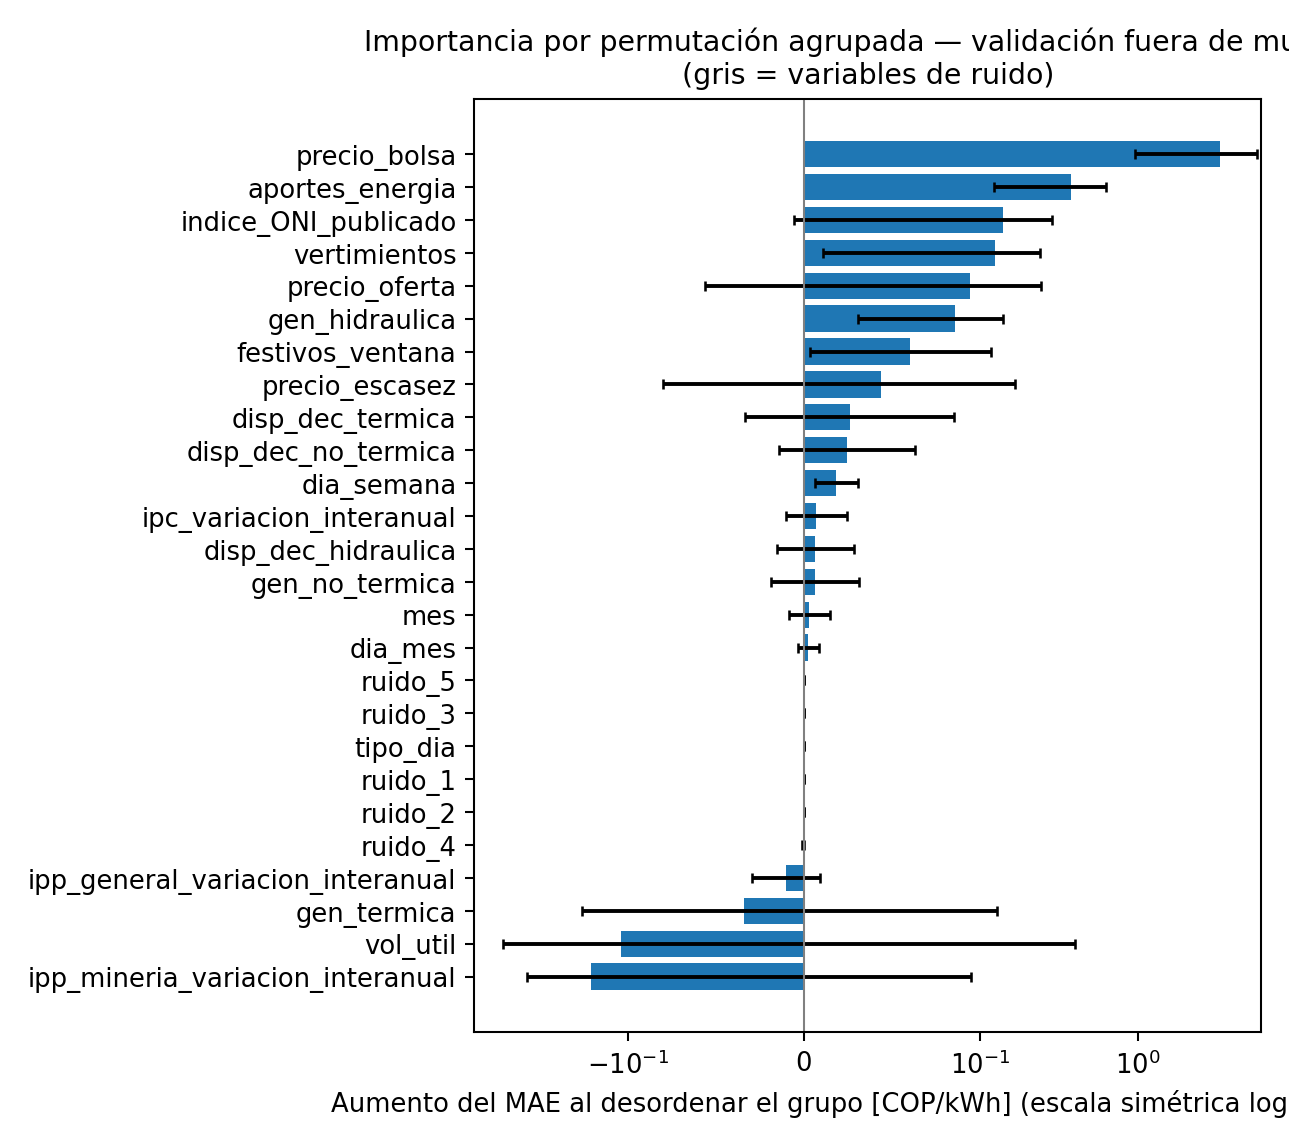

In [14]:
# ============================================================
# Gráfico: importancia agrupada (barras = media entre pliegues; línea = desviación entre pliegues)
# ============================================================
g_plot = resumen_g.copy()
g_plot["es_ruido"] = g_plot.index.str.startswith("ruido_")
g_plot = g_plot.iloc[::-1]
fig, ax = plt.subplots(figsize=(ANCHO_PAGINA, alto_pagina(9, 8)))
colores = ["lightgrey" if r else "tab:blue" for r in g_plot["es_ruido"]]
ax.barh(g_plot.index, g_plot["media"], xerr=g_plot["desv_entre_pliegues"], color=colores, capsize=2)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xscale("symlog", linthresh=0.1)      # el precio domina; la escala simétrica logarítmica deja ver el resto
ax.set_xlabel("Aumento del MAE al desordenar el grupo [COP/kWh] (escala simétrica logarítmica)")
ax.set_title("Importancia por permutación agrupada — validación fuera de muestra\n(gris = variables de ruido)")
a_escala(fig)
plt.tight_layout()
plt.show();

## 7. Regla de selección

**Qué se hace.** Se decide qué grupos (variables de origen) se conservan con una regla de **tres criterios** que debe cumplir cada uno.

1. **Supera al ruido:**
2. **Es consistente en el tiempo:**
3. **Es estable entre semillas:**

In [15]:
# ============================================================
# 7. Aplicación de la regla de selección
# ============================================================
MIN_PLIEGUES_POSITIVOS = 4      # de 5
MIN_FRACCION_SEMILLAS = 0.8     # al menos 4 de 5 semillas

# Criterios 1 y 2 con todas las semillas promediadas.
piso_ruido = resumen_g.loc[sondas, "media"].max()
resumen_g["supera_ruido"] = resumen_g["media"] > piso_ruido
resumen_g["consistente"] = resumen_g["pliegues_positivos"] >= MIN_PLIEGUES_POSITIVOS

# Criterio 3: la misma regla (1 y 2) aplicada por separado a cada semilla.
cumple_por_semilla = {}
for s in SEMILLAS:
    pp = reg_grupos[reg_grupos["semilla"] == s].groupby(["pliegue", "grupo"])["importancia"].mean().unstack("pliegue")
    media_s, pos_s = pp.mean(axis=1), (pp > 0).sum(axis=1)
    cumple_por_semilla[s] = (media_s > media_s[sondas].max()) & (pos_s >= MIN_PLIEGUES_POSITIVOS)
resumen_g["fraccion_semillas"] = pd.DataFrame(cumple_por_semilla).mean(axis=1)
resumen_g["estable"] = resumen_g["fraccion_semillas"] >= MIN_FRACCION_SEMILLAS

resumen_g["pasa_regla"] = resumen_g["supera_ruido"] & resumen_g["consistente"] & resumen_g["estable"]
resumen_g.loc[sondas, "pasa_regla"] = False                  # las de ruido nunca se seleccionan

cols_vista = ["media", "pliegues_positivos", "fraccion_semillas", "supera_ruido", "consistente", "estable", "pasa_regla"]
print(f"Piso de ruido: {piso_ruido:.4f} COP/kWh\n")
print(resumen_g.loc[~resumen_g.index.isin(sondas), cols_vista].round(3).to_string())
pasan = resumen_g.index[resumen_g["pasa_regla"]].tolist()
print(f"\nPasan la regla ({len(pasan)}): {pasan}")

Piso de ruido: 0.0000 COP/kWh

                                  media  pliegues_positivos  fraccion_semillas  supera_ruido  consistente  estable  pasa_regla
precio_bolsa                      3.325                   5                1.0          True         True     True        True
aportes_energia                   0.377                   5                1.0          True         True     True        True
indice_ONI_publicado              0.140                   4                0.6          True         True    False       False
vertimientos                      0.126                   4                0.8          True         True     True        True
precio_oferta                     0.095                   3                0.2          True        False    False       False
gen_hidraulica                    0.086                   5                0.8          True         True     True        True
festivos_ventana                  0.060                   4                0.4  

**Lectura de la regla.** Pasan **cinco** variables de origen: `precio_bolsa`, `aportes_energia`, `vertimientos`, `gen_hidraulica` y `dia_semana`.

- **Supera el ruido y es consistente, pero no estable entre semillas**: el **`indice_ONI_publicado`** (0,140; 4 de 5 pliegues, pero solo **3 de 5 semillas**), `disp_dec_termica` (3 de 5 semillas) y `disp_dec_no_termica` (2 de 5).
- **Ni consistente ni estable**
- **Sin aporte**
- **Se cancelan con el objetivo de ventana**

### 7.1 Revisión con criterio de dominio y ablación

**Qué se hace.** Las variables que pasan la regla estadística se revisan contra lo que el EDA había advertido.

In [16]:
# ============================================================
# 7.1 Ablación: ¿cambia el pronóstico si se quitan las variables marcadas como dudosas por el EDA?
# ============================================================
SOSPECHOSAS_EDA = [g for g in grupos if g.startswith(("ipc_", "ipp_")) or g == "precio_escasez"]
TOLERANCIA_ABLACION = 0.005           # 0,5 puntos porcentuales de la razón de MAE
SEMILLAS_ABLACION = SEMILLAS[:3]


def razon_media_conjunto(columnas, semillas=SEMILLAS_ABLACION):
    """Razón MAE/persistencia por pliegue (promediada sobre semillas) de un modelo con las columnas dadas."""
    por_pl = []
    for k, (fa, vi, vf) in enumerate(PLIEGUES):
        aj, va = datos_pliegue(fa, vi, vf)
        por_pl.append(np.mean([razon_vs_persistencia(construir_modelo(s, **PARAMETROS_MODELO), aj, va, columnas)[0]
                               for s in semillas]))
    return por_pl


def columnas_de(lista_grupos):
    return [c for g in lista_grupos for c in grupos[g]]


decision_dominio = {}
base_sel = list(pasan)
razon_con = razon_media_conjunto(columnas_de(base_sel))
print(f"Conjunto que pasa la regla ({len(base_sel)} variables): razón media {np.mean(razon_con):.4f}")
for g in [s for s in base_sel if s in SOSPECHOSAS_EDA]:
    razon_sin = razon_media_conjunto(columnas_de([x for x in base_sel if x != g]))
    perdida = np.mean(razon_sin) - np.mean(razon_con)         # >0: quitarla empeora el pronóstico
    conserva = perdida > TOLERANCIA_ABLACION
    decision_dominio[g] = (perdida, conserva)
    print(f"   sin {g:38s} razón media {np.mean(razon_sin):.4f}  (cambio {perdida:+.4f})  -> "
          f"{'se conserva' if conserva else 'se descarta (parsimonia; marcada como espuria por el EDA)'}")
if not decision_dominio:
    print("   Ninguna variable marcada como dudosa por el EDA pasó la regla estadística: no hay nada que revisar.")

seleccion_final = [g for g in base_sel if decision_dominio.get(g, (0, True))[1]]
print(f"\nSelección final ({len(seleccion_final)} variables de origen): {seleccion_final}")

Conjunto que pasa la regla (5 variables): razón media 0.9433
   Ninguna variable marcada como dudosa por el EDA pasó la regla estadística: no hay nada que revisar.

Selección final (5 variables de origen): ['precio_bolsa', 'aportes_energia', 'vertimientos', 'gen_hidraulica', 'dia_semana']


**Lectura.** La revisión de dominio **no tuvo nada que descartar**: ninguna de las variables marcadas por el EDA como espurias (las cuatro variaciones de IPC/IPP y `precio_escasez`) pasó la regla estadística.

In [17]:
# ============================================================
# 7.2 Verificación de conjunto: ¿cuánto aporta cada nivel de información?
# ============================================================
calendario_obj = [g for g in ["tipo_dia", "dia_semana", "mes"] if g in grupos]   # grupos del calendario de la fecha objetivo
conjuntos = {
    "Solo el precio (sus rezagos, medias y cambios)":   ["precio_bolsa"],
    "Precio + calendario de la fecha objetivo":         ["precio_bolsa"] + calendario_obj,
    "Variables seleccionadas":                           seleccion_final,
    "Todas las candidatas (sin ruido)":                  [g for g in grupos if not g.startswith("ruido_")],
}
filas = []
for nombre, gs in conjuntos.items():
    razones = razon_media_conjunto(columnas_de(gs))
    filas.append({"conjunto": nombre, "n_variables": len(gs), **{f"P{k + 1}": r for k, r in enumerate(razones)},
                  "razon_media": float(np.mean(razones))})
verificacion = pd.DataFrame(filas)
print("Razón MAE modelo / MAE persistencia por pliegue (menor es mejor):")
print(verificacion.round(3).to_string(index=False))
mae_pers_medio = np.mean(mae_persistencia_pliegues)
print(f"\nPara dimensionar: el MAE de la persistencia promedia {mae_pers_medio:.0f} COP/kWh en los pliegues, así que "
      f"una diferencia de 0,01 en la razón equivale a ~{0.01 * mae_pers_medio:.1f} COP/kWh.")

Razón MAE modelo / MAE persistencia por pliegue (menor es mejor):
                                      conjunto  n_variables    P1    P2    P3    P4    P5  razon_media
Solo el precio (sus rezagos, medias y cambios)            1 0.963 0.921 1.009 0.944 0.936        0.954
      Precio + calendario de la fecha objetivo            4 0.972 0.921 0.999 0.934 0.927        0.951
                       Variables seleccionadas            5 0.974 0.909 0.965 0.908 0.960        0.943
              Todas las candidatas (sin ruido)           21 0.957 0.931 0.952 0.907 0.914        0.932

Para dimensionar: el MAE de la persistencia promedia 52 COP/kWh en los pliegues, así que una diferencia de 0,01 en la razón equivale a ~0.5 COP/kWh.


**Lectura.** Las diferencias entre los conjuntos son pequeñas y caen dentro de la variabilidad entre pliegues.

### Resumen de la selección

| Variable de origen | Decisión | Qué aporta |
|---|---|---|
| `precio_bolsa` (su dinámica) | **Seleccionada** | La parte autorregresiva: correlaciona 0,869 con el promedio de los 30 días siguientes |
| `aportes_energia` | **Seleccionada** | La entrada de agua al sistema. Su **cambio a 30 días** es lo que el precio todavía no refleja |
| `vertimientos` | **Seleccionada** | Abundancia de agua (casi binaria) |
| `gen_hidraulica` | **Seleccionada** | Cuánta energía se está produciendo con agua; consistente en los cinco pliegues |
| `dia_semana` | **Seleccionada** | Una ventana de 30 días no contiene el mismo número de cada día: efecto pequeño pero sistemático |
| `indice_ONI_publicado` | **Descartada como predictor; se conserva para segmentar** | Sigue correlacionando 0,470 con el objetivo, pero su aporte *sobre el precio ya conocido* no es estable (3 de 5 semillas) |
| `vol_util` | Descartada | Importancia media negativa. Descontada la historia del precio, su relación **cambia de signo**: lo que queda es reversión a la media, no señal hidrológica |
| `precio_oferta`, `gen_termica` | Descartadas | Las más correlacionadas con el precio (0,64 y 0,79) porque **son** el precio: se fija con la oferta de la planta marginal. Añadirlas empeoró el SARIMAX en 5,2 COP/kWh |
| `tipo_dia`, `mes` | Descartadas | Se cancelan sobre un promedio de 30 días (0,000 y 0,003) |
| `festivos_ventana` | Descartada | La forma pertinente de meter el calendario en este objetivo (0,060, veinte veces el `mes`), pero solo 2 de 5 semillas |
| `demanda` | Descartada por redundancia | Casi la suma de las generaciones por tecnología |
| Bloque macro (IPC/IPP) | Descartado | Espurio (EDA) y sin aporte estable |
| Disponibilidad declarada | Descartada | El total es combinación lineal exacta; los tres tipos superan el ruido pero no son estables |

**Una aclaración que el documento debe recoger.** La exclusión del volumen útil y del precio de oferta es sobre **valor predictivo incremental a treinta días**, no sobre relevancia física.

## 8. Interpretación con SHAP

**Qué se hace.** Con las variables ya seleccionadas se calculan los **valores SHAP**: cuánto *empujó* cada variable cada predicción concreta, con signo y magnitud.

- **Fuera de muestra.**
- **Agregado por variable de origen.**
- **Unidades.** El modelo predice `log(P(t+30)/P(t))`, así que los valores SHAP están en esa escala: 0,10 equivale a empujar la predicción ~10 % hacia arriba.
- **Por régimen ENSO.**

Valores SHAP: 3652 predicciones fuera de muestra x 38 columnas
Desviación máxima de la aditividad: 7.45e-08  (correcto)

Importancia SHAP por variable de origen (media del valor absoluto, escala del cambio logarítmico a 30 días):
precio_bolsa       0.0657
aportes_energia    0.0233
gen_hidraulica     0.0157
vertimientos       0.0076
dia_semana         0.0024


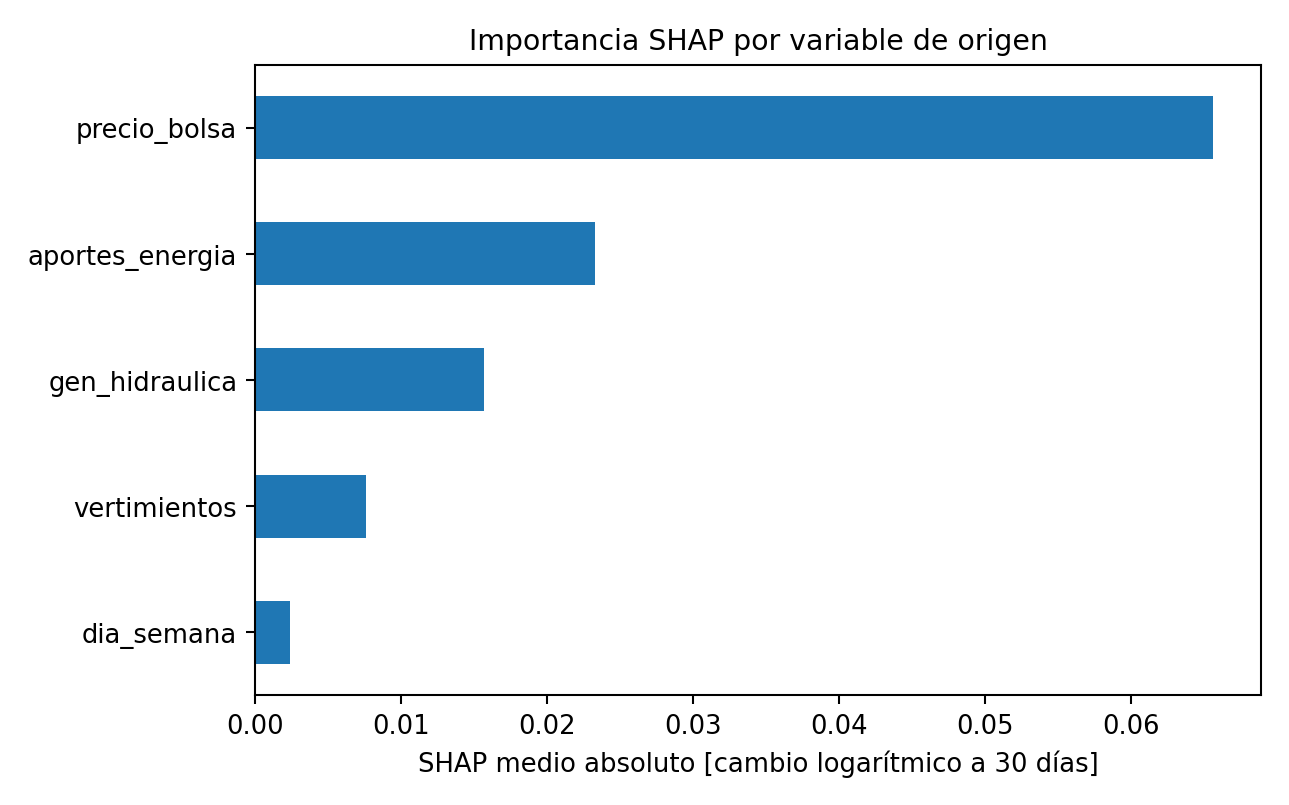

In [18]:
# ============================================================
# 8. SHAP del modelo con las variables seleccionadas, fuera de muestra y por variable de origen
# ============================================================
import xgboost as xgb

cols_sel = columnas_de(seleccion_final)
bloques_shap, bloques_X, bloques_idx, desvios = [], [], [], []
for k, (fa, vi, vf) in enumerate(PLIEGUES, start=1):
    aj, va = datos_pliegue(fa, vi, vf)
    modelo = construir_modelo(42, **PARAMETROS_MODELO)
    modelo.fit(aj[cols_sel], np.log(aj["objetivo"].values / aj["precio_hoy"].values))
    # TreeSHAP exacto, nativo de XGBoost: pred_contribs devuelve una columna por variable y, al final, el
    # valor base. Es el mismo algoritmo que shap.TreeExplainer, sin depender de su lectura del modelo.
    contribs = modelo.get_booster().predict(xgb.DMatrix(va[cols_sel], feature_names=list(cols_sel)), pred_contribs=True)
    # Propiedad aditiva: valor base + contribuciones = predicción. Si no se cumple, los valores no se
    # pueden interpretar y no debe seguirse adelante.
    desvios.append(np.abs(contribs.sum(axis=1) - modelo.predict(va[cols_sel], output_margin=True)).max())
    bloques_shap.append(contribs[:, :-1]); bloques_X.append(va[cols_sel]); bloques_idx.append(va.index)

shap_vals = np.vstack(bloques_shap)
X_shap = pd.concat(bloques_X)
print(f"Valores SHAP: {shap_vals.shape[0]} predicciones fuera de muestra x {shap_vals.shape[1]} columnas")
print(f"Desviación máxima de la aditividad: {max(desvios):.2e}  ({'correcto' if max(desvios) < 1e-3 else 'REVISAR'})")

# Agregación por variable de origen: se suman los SHAP de sus derivadas fila a fila.
idx_col = {c: i for i, c in enumerate(cols_sel)}
shap_grupo = pd.DataFrame({g: shap_vals[:, [idx_col[c] for c in grupos[g] if c in idx_col]].sum(axis=1)
                           for g in seleccion_final}, index=X_shap.index)
shap_global = shap_grupo.abs().mean().sort_values(ascending=False).rename("shap_medio_abs")
print("\nImportancia SHAP por variable de origen (media del valor absoluto, escala del cambio logarítmico a 30 días):")
print(shap_global.round(4).to_string())

shap_grupo.abs().mean().sort_values().plot(kind="barh", figsize=(ANCHO_PAGINA, alto_pagina(8, 5)))
plt.xlabel("SHAP medio absoluto [cambio logarítmico a 30 días]")
plt.title("Importancia SHAP por variable de origen")
a_escala(plt.gcf())
plt.tight_layout()
plt.show();

**Lectura de la importancia SHAP** (escala del cambio logarítmico del promedio a 30 días.

- **Orden:** `precio_bolsa` (0,066), `aportes_energia` (0,023), `gen_hidraulica` (0,016), `vertimientos` (0,008) y `dia_semana` (0,002), sobre **3.652 predicciones fuera de muestra y 38 columnas**.
- **El orden coincide con el de la permutación**
- **Las tres variables hidrológicas suman 0,047**

Correlación de Spearman entre el valor de la variable y su aporte SHAP:
precio_bolsa      -0.77
aportes_energia   -0.37
gen_hidraulica     0.47
vertimientos       0.44
dia_semana        -0.65


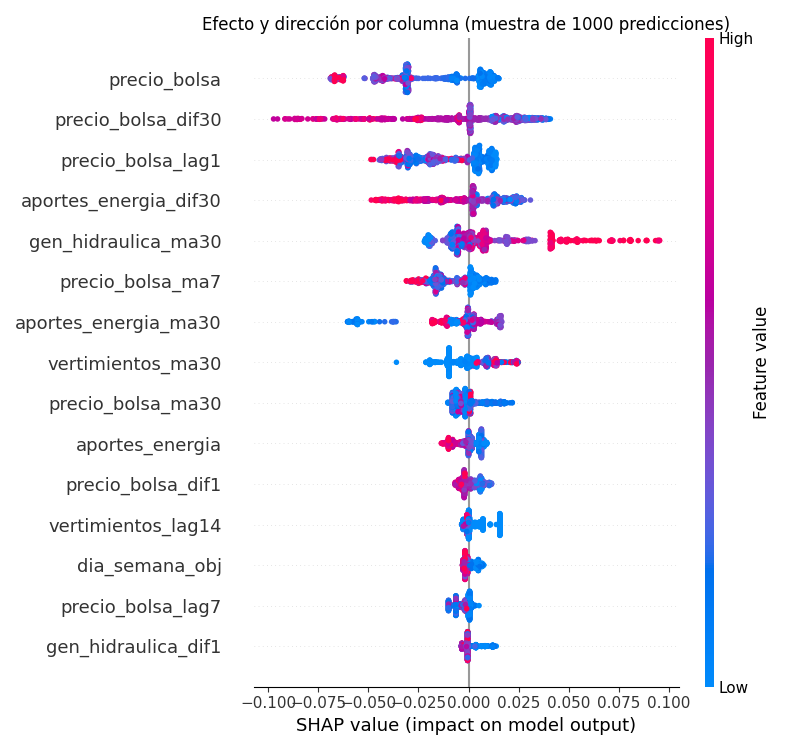

In [19]:
# ============================================================
# 8.1 Dirección del efecto: ¿empuja el precio hacia arriba o hacia abajo?
# ============================================================
# Para cada variable de origen, se resume el efecto con la correlación entre el valor de su columna principal
# (la de la variable misma, sin derivar) y su SHAP agregado: positiva = valores altos empujan el precio al alza.
# Se usa la columna principal porque es la que tiene una lectura directa ("más volumen útil"); en los grupos
# cuya columna principal es una derivada (p. ej. tipo_dia_obj), es esa misma.
direccion = {}
for g in seleccion_final:
    col_principal = g if g in X_shap.columns else (f"{g}_obj" if f"{g}_obj" in X_shap.columns else grupos[g][0])
    direccion[g] = spearmanr(X_shap[col_principal], shap_grupo[g]).correlation
direccion = pd.Series(direccion, name="correlacion_valor_vs_shap").reindex(shap_global.index)
print("Correlación de Spearman entre el valor de la variable y su aporte SHAP:")
print(direccion.round(2).to_string())

# Nube de puntos de las columnas con mayor aporte (si 'shap' está instalada).
try:
    import shap
    muestra = X_shap.sample(min(1000, len(X_shap)), random_state=42)
    pos = [X_shap.index.get_loc(i) for i in muestra.index]
    shap.summary_plot(shap_vals[pos], muestra, max_display=15, show=False)
    plt.title("Efecto y dirección por columna (muestra de 1000 predicciones)")
    plt.tight_layout()
    plt.show();
except ImportError:
    print("\n(shap no está instalado; se omite la nube de puntos. Instalar con: pip install shap)")

**Cómo leer los signos.

- `precio_bolsa` (−0,77): cuanto más alto es el precio hoy, menor es el cambio esperado: **reversión a la media**, esperable.
- `dia_semana` (−0,65): efecto de composición de la ventana, no una relación física.
- `gen_hidraulica` (+0,47) y `vertimientos` (+0,44): **cuidado con estas lecturas.** No significan que generar con agua o verter suba el precio.
- `aportes_energia` (−0,37): más aportes, menor cambio esperado.

SHAP medio absoluto por régimen ENSO del origen:
                 El Niño (n=1096)  Neutral (n=1711)  La Niña (n=845)
precio_bolsa               0.0819            0.0627           0.0506
aportes_energia            0.0171            0.0237           0.0306
gen_hidraulica             0.0107            0.0106           0.0324
vertimientos               0.0070            0.0071           0.0092
dia_semana                 0.0026            0.0021           0.0025


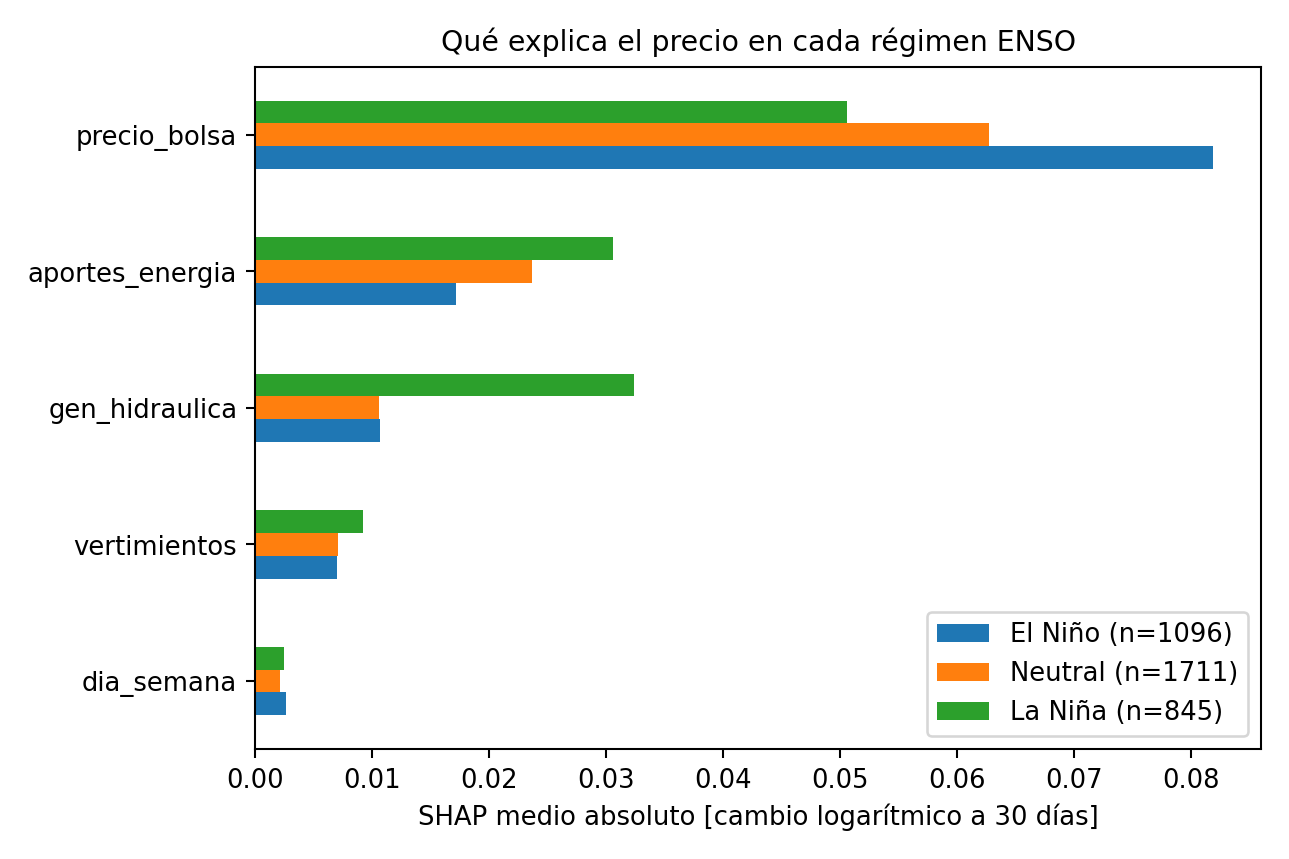

In [20]:
# ============================================================
# 8.2 SHAP por régimen climático: El Niño, Neutral, La Niña
# ============================================================
# La fase se toma del ONI PUBLICADO en el origen: es la que ya se conocía el día del pronóstico.
oni_origen = X.loc[X_shap.index, "indice_ONI_publicado"] if "indice_ONI_publicado" in X.columns else None
fase = pd.Series(np.select([oni_origen >= 0.5, oni_origen <= -0.5], ["El Niño", "La Niña"], default="Neutral"),
                 index=X_shap.index)

columnas_fase = []
for etiqueta in ["El Niño", "Neutral", "La Niña"]:
    m = (fase == etiqueta).values
    if m.sum():
        columnas_fase.append(shap_grupo.loc[m].abs().mean().rename(f"{etiqueta} (n={m.sum()})"))
shap_fase = pd.concat(columnas_fase, axis=1).loc[shap_global.index]
print("SHAP medio absoluto por régimen ENSO del origen:")
print(shap_fase.round(4).to_string())

shap_fase.iloc[::-1].plot(kind="barh", figsize=(ANCHO_PAGINA, alto_pagina(9, 6)))
plt.xlabel("SHAP medio absoluto [cambio logarítmico a 30 días]")
plt.title("Qué explica el precio en cada régimen ENSO")
a_escala(plt.gcf())
plt.tight_layout()
plt.show();

**Lectura por régimen ENSO** (1.096 orígenes de El Niño, 1.711 neutrales y 845 de La Niña, de los bloques de validación 2013–2022).

- **El precio de hoy pesa más en El Niño**
- **La hidrología pesa más en La Niña**
- **`vertimientos` sigue el mismo patrón**
- **`dia_semana` es indiferente al régimen**

## 9. Dataset final y archivos de salida

**Qué se hace.** Se guarda el conjunto seleccionado en el formato que consumen los notebooks de modelado y las tablas que sustentan cada decisión.

In [21]:
# ============================================================
# 9. Archivos de salida
# ============================================================
# --- Dataset seleccionado (contrato con los notebooks de modelado) ---
sel_cols_orden = [c for c in predictoras if variable_base(c) in seleccion_final]
# El índice ONI no pasó la regla como predictor, pero se conserva en el archivo porque los
# notebooks de modelos lo necesitan para CLASIFICAR la fase ENSO y reportar el error segmentado
# por régimen. Va fuera de las predictoras: NO entra a ningún modelo.
NO_MODELAN = ["fecha", "fecha_objetivo", "precio_hoy", "objetivo", "objetivo_dia30",
              "indice_ONI_publicado"]
salida = X[["fecha", "fecha_objetivo", "precio_hoy"] + sel_cols_orden
           + ["objetivo", "objetivo_dia30", "indice_ONI_publicado"]]
salida.to_csv(os.path.join(PROC, "4_dataset_seleccion.csv"), index=False)

# --- Importancia por columna (informativa: sirve para elegir la derivada más representativa de cada grupo) ---
imp_col = (reg_indiv.groupby(["pliegue", "variable"])["importancia"].mean().unstack("pliegue"))
tabla_col = pd.DataFrame({"importancia": imp_col.mean(axis=1), "desv_std": imp_col.std(axis=1),
                          "pliegues_positivos": (imp_col > 0).sum(axis=1)})
tabla_col["grupo"] = [variable_base(c) for c in tabla_col.index]
tabla_col = tabla_col.sort_values("importancia", ascending=False).reset_index().rename(columns={"index": "variable"})
tabla_col.to_csv(os.path.join(PROC, "4_importancia_permutacion.csv"), index=False)

# --- Importancia por variable de origen y decisión, con su motivo ---
def motivo(g):
    if g.startswith("ruido_"):
        return "variable de ruido (control)"
    r = resumen_g.loc[g]
    if g in decision_dominio and not decision_dominio[g][1]:
        return "pasa la regla; descartada en la revisión de dominio (marcada como espuria por el EDA; la ablación no muestra pérdida)"
    if r["pasa_regla"]:
        return "pasa la regla (supera al ruido, consistente y estable)"
    fallas = [n for n, ok in (("no supera al ruido", r["supera_ruido"]), ("no es consistente entre pliegues", r["consistente"]),
                              ("no es estable entre semillas", r["estable"])) if not ok]
    return "; ".join(fallas)

decision = resumen_g.copy()
decision["decision"] = ["seleccionada" if g in seleccion_final else "descartada" for g in decision.index]
decision["motivo"] = [motivo(g) for g in decision.index]
decision.index.name = "grupo"
decision[["media", "desv_entre_pliegues", "pliegues_positivos", "fraccion_semillas", "n_columnas",
          "decision", "motivo"]].to_csv(os.path.join(PROC, "4_importancia_por_bloque.csv"))

# --- SHAP por variable de origen y por régimen ---
shap_global.to_csv(os.path.join(PROC, "4_importancia_shap.csv"), header=True)
shap_fase.to_csv(os.path.join(PROC, "4_importancia_shap_por_fase.csv"))

# --- Referencias del protocolo sobre la PRUEBA (solo persistencia y media; ningún modelo se evalúa aquí) ---
def smape(y_true, y_pred):
    """SMAPE en porcentaje (O'Connor et al., 2025): no se distorsiona con precios cercanos a cero."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs(y_true - y_pred) / ((np.abs(y_true) + np.abs(y_pred)) / 2)) * 100)

def evaluar(nombre, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {"configuracion": nombre, "MAE": float(np.mean(np.abs(y_true - y_pred))),
            "RMSE": float(np.sqrt(np.mean((y_true - y_pred) ** 2))), "SMAPE": smape(y_true, y_pred)}

y_prueba, pers_prueba = prueba["objetivo"].values, prueba["precio_hoy"].values
referencias = pd.DataFrame([
    evaluar("Referencia: persistencia (P de hoy)", y_prueba, pers_prueba),
    evaluar("Referencia: media del entrenamiento", y_prueba, np.full(len(y_prueba), entren["objetivo"].mean())),
]).round(1)
referencias.to_csv(os.path.join(PROC, "4_metricas_modelo_base.csv"), index=False)

print(f"4_dataset_seleccion.csv: {salida.shape[0]} filas x {salida.shape[1]} columnas "
      f"({len(sel_cols_orden)} predictoras de {len(seleccion_final)} variables de origen)")
print("\nDecisión por variable de origen:")
print(decision.loc[~decision.index.str.startswith("ruido_"), ["media", "pliegues_positivos", "fraccion_semillas", "decision", "motivo"]]
      .round(3).to_string())
print("\nReferencias del protocolo sobre la prueba (no se usaron para decidir):")
print(referencias.to_string(index=False))

4_dataset_seleccion.csv: 5754 filas x 44 columnas (38 predictoras de 5 variables de origen)

Decisión por variable de origen:
                                  media  pliegues_positivos  fraccion_semillas      decision                                                                              motivo
grupo                                                                                                                                                                           
precio_bolsa                      3.325                   5                1.0  seleccionada                              pasa la regla (supera al ruido, consistente y estable)
aportes_energia                   0.377                   5                1.0  seleccionada                              pasa la regla (supera al ruido, consistente y estable)
indice_ONI_publicado              0.140                   4                0.6    descartada                                                        no es estable entr

- La selección final tiene **5 variables de origen** y **38 columnas predictoras** (sus derivadas), en `4_dataset_seleccion.csv` (5.754 filas × 44 columnas).
- El archivo lleva además tres columnas que **no son predictoras**: `objetivo_dia30` —el precio del día 30, como lectura secundaria— y el `indice_ONI_publicado`, que los notebooks de modelos usan para clasificar la fase ENSO al reportar el error segmentado.
- Las referencias de la prueba, sobre el objetivo de ventana: la persistencia da **MAE 145,7, RMSE 232,2 y SMAPE 30,5**, y la media del entrenamiento, 292,6, 421,4 y 69,8.
- El entrenamiento empieza el 2010-06-30 por los rezagos largos del ONI, que se siguen construyendo aunque el índice no entre como predictor.
- **Este archivo es el punto de partida de todos los modelos.**

## 10. Qué sigue y limitaciones

- Volver a ejecutar `5_SARIMAX_modelo_base.ipynb`: su entrada es `4_dataset_seleccion.csv`, que cambió con esta versión.
- Usar el mismo archivo como entrada de XGBoost, LSTM y el híbrido BiLSTM con atención y descomposición.
- Reportar en el documento: la tabla de decisión (`4_importancia_por_bloque.csv`), la comparación con el piso de ruido, y la lectura por régimen ENSO.
1. **Importancia no es causalidad.**
2. **Las variables exógenas se usan observadas en `t`.**
3. **La selección depende del modelo auxiliar y del horizonte.**
4. **Un solo método de importancia.**
5. **La verificación de conjunto de la sección 7.2 favorece a las seleccionadas**, porque las variables se eligieron con esos mismos pliegues.
6. **`demanda` se descartó por redundancia, no por irrelevancia**
7. **~~La disponibilidad declarada quedó fuera por un problema de cálculo~~ — RESUELTO el 18/10/2026.** El promedio por recurso se reemplazó por la **suma** en `2_DataProcessing.ipynb`, y las tres disponibilidades por tipo volvieron a la lista de candidatas (sección 2.2).